In [1]:
import numpy as np
import random
from scipy.stats import unitary_group, ortho_group
from scipy.linalg import eigh
import scipy.linalg as la
import matplotlib.pyplot as plt
from collections import defaultdict
from numpy.random import default_rng
from math import cos, sin
import scipy.optimize as opt
from mpl_toolkits.mplot3d import Axes3D
import distribution.distribution_functions.random_mps_v2 as rmps


In [2]:
# Parameters  
d = 2 
L = 4
n = int(d**(L)) # dimension, I don't think it is use.
n_samples = 1000  # Number of random matrices to generate
chi_max = 4

# Generate random matrices and collect their entries
original_samples = np.zeros((n_samples, n), dtype=complex)
for i in range(n_samples):
    list_M, list_rho = rmps.draw_random_mps(L, chi_max, d, None)
    original_samples[i], _ = rmps.vector_state_from_mps_v2(list_M, L, d)


# Apply a fixed unitary transformation to all matrices
U_fixed = unitary_group.rvs(n)
transformed_samples = np.zeros((n_samples, n), dtype=complex)
for i in range(n_samples):
    transformed_samples[i] = np.dot(U_fixed, original_samples[i])

Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) = 2 x 1
Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) = 2 x 1
Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) = 2 x 1
Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) = 2 x 1
Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) = 2 x 1
Sampling MPS tensor M@0, dim(M_0) = 1 x 2
Sampling MPS tensor M@1, dim(M_1) = 2 x 4
Sampling MPS tensor M@2, dim(M_2) = 4 x 2
Sampling MPS tensor M@3, dim(M_3) 

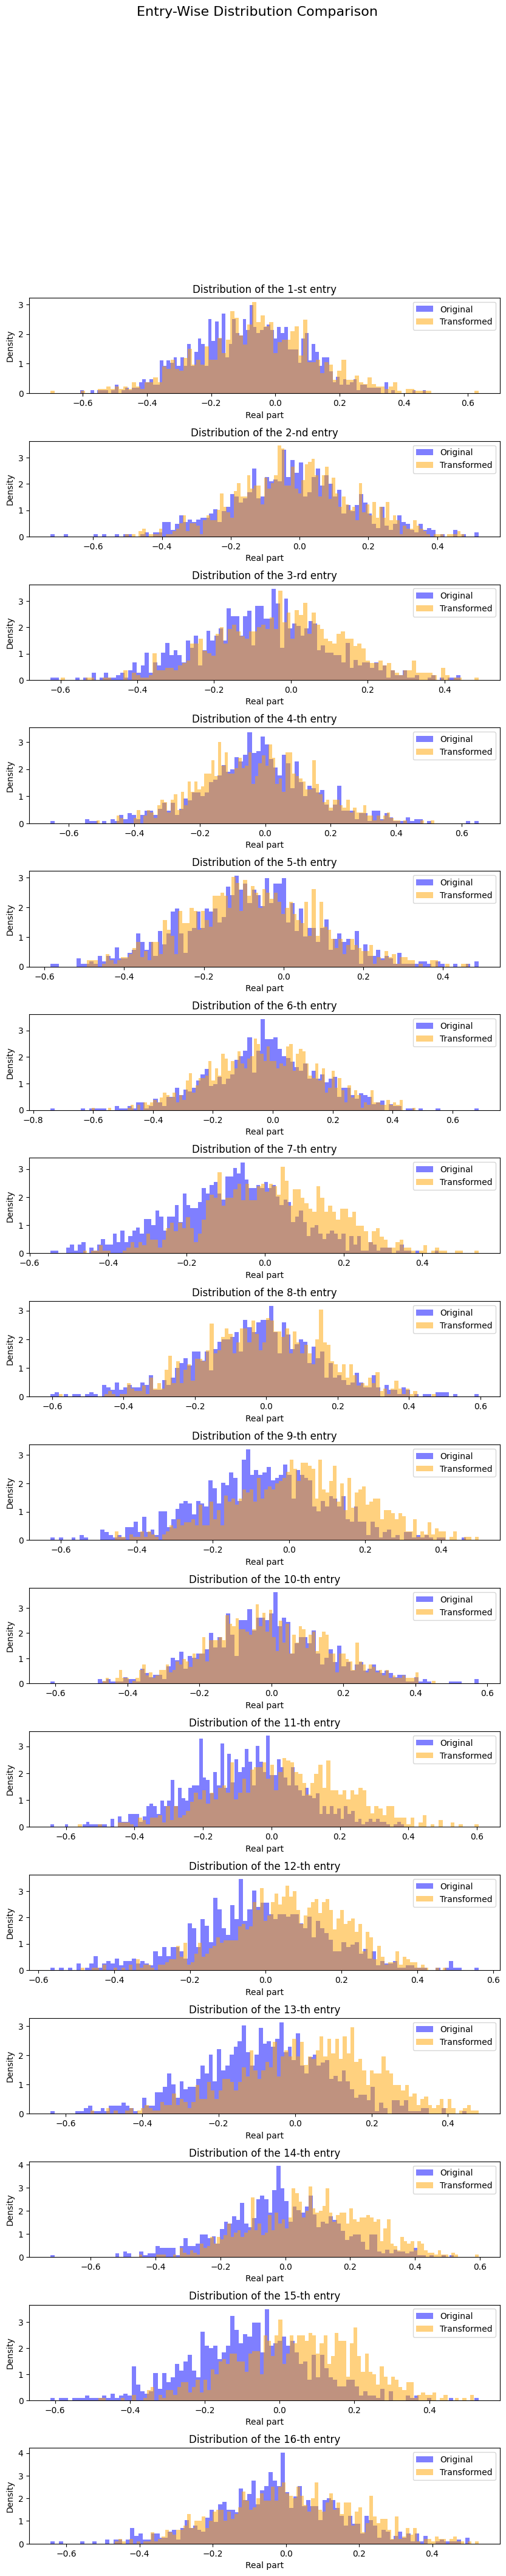

In [3]:
# Plot distribution of each entry
fig, axes = plt.subplots(n, figsize=(10, 3 * n))  # <-- increased vertical size
fig.suptitle("Entry-Wise Distribution Comparison", fontsize=16)
plt.subplots_adjust(hspace=0.5)  # <-- add more vertical spacing
bins = 100
for i in range(n):
    # Extract real parts of the (i, j) entries
    original_data = original_samples[:, i].real
    transformed_data = transformed_samples[:, i].real

    # Plot histograms
    axes[i].hist(original_data, bins=bins, density=True, alpha=0.5, color="blue", label="Original")
    axes[i].hist(transformed_data, bins=bins, density=True, alpha=0.5, color="orange", label="Transformed")
    
    # Title and labels
    if i == 0:
        axes[i].set_title(f"Distribution of the {i+1}-st entry")
    elif i == 1:
        axes[i].set_title(f"Distribution of the {i+1}-nd entry")
    elif i == 2:
        axes[i].set_title(f"Distribution of the {i+1}-rd entry")
    else:
        axes[i].set_title(f"Distribution of the {i+1}-th entry")
    axes[i].set_xlabel("Real part")
    axes[i].set_ylabel("Density")
    axes[i].legend()

# plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()
